--- ÉTAPE 1 : Extraction et nettoyage des données ---


[*********************100%***********************]  5 of 5 completed


• Dimensions du DataFrame (Jours x Actifs) : (752, 5)
• Valeurs manquantes : 0


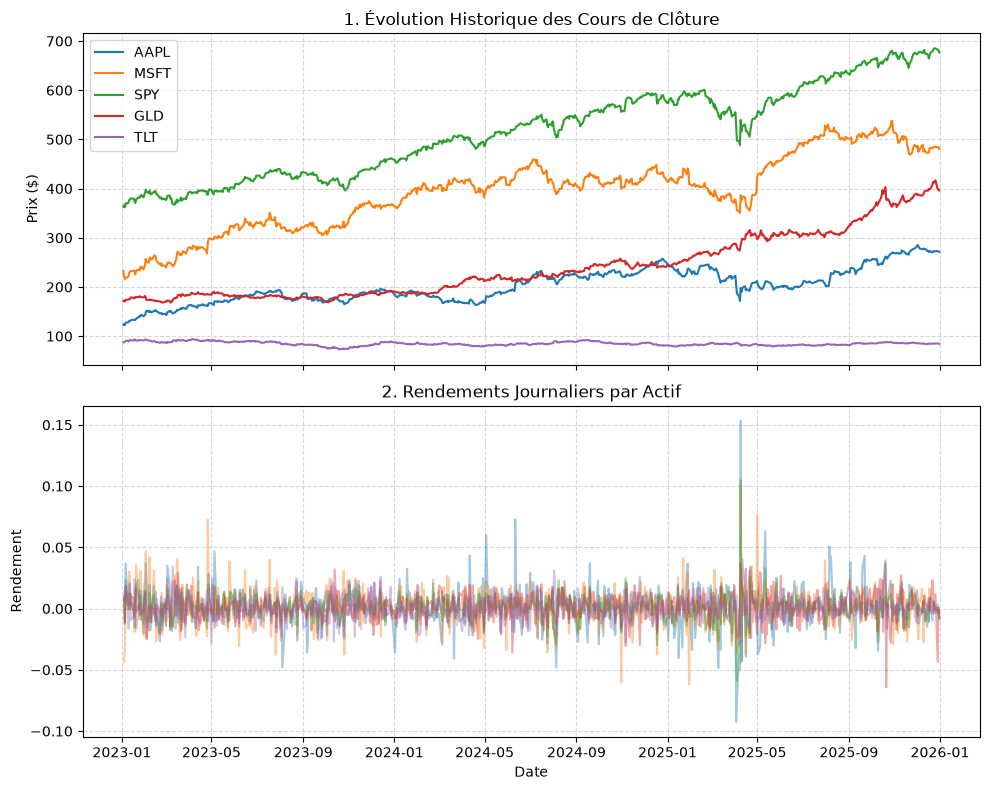

In [2]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# 1. Définition de l'univers d'investissement
tickers = ["AAPL", "MSFT", "SPY", "GLD", "TLT"]

print("--- ÉTAPE 1 : Extraction et nettoyage des données ---")
data = yf.download(tickers, start="2023-01-01", end="2026-01-01")['Close']

if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.droplevel(1)

# Tests de contrôle de base
print(f"• Dimensions du DataFrame (Jours x Actifs) : {data.shape}")
print(f"• Valeurs manquantes : {data.isnull().sum().sum()}")

# Calcul des rendements journaliers
returns = data.pct_change().dropna()

# --- GRAPHIQUE 1 : Évolution des Prix de Clôture ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

for t in tickers:
    ax1.plot(data.index, data[t], label=t)
ax1.set_title("1. Évolution Historique des Cours de Clôture")
ax1.set_ylabel("Prix ($)")
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# --- GRAPHIQUE 2 : Rendements Journaliers ---
for t in tickers:
    ax2.plot(returns.index, returns[t], alpha=0.4, label=t)
ax2.set_title("2. Rendements Journaliers par Actif")
ax2.set_ylabel("Rendement")
ax2.set_xlabel("Date")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

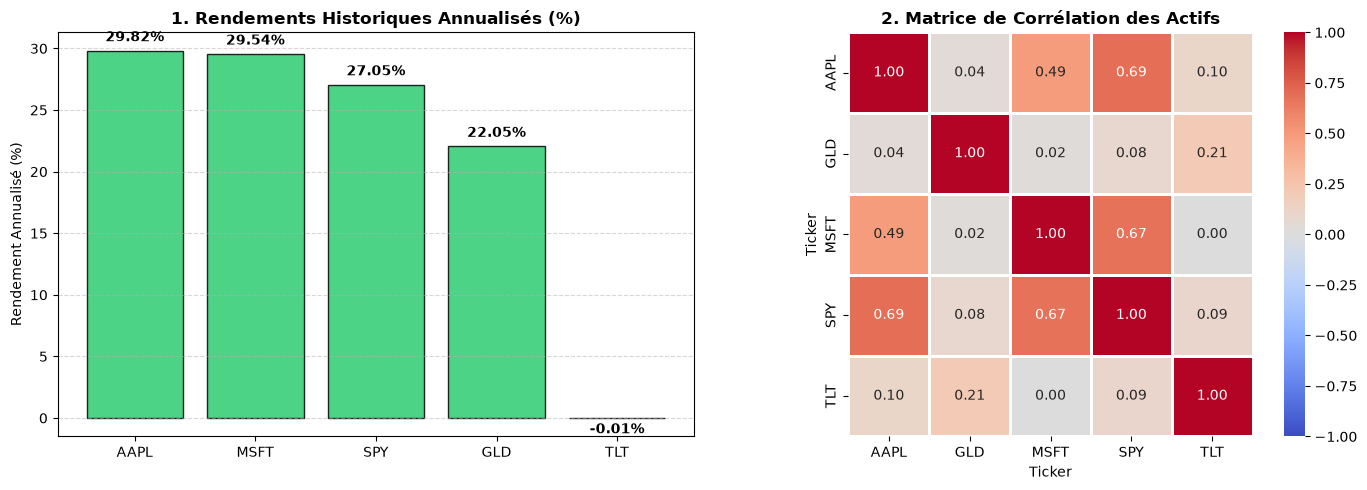

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calcul des rendements annualisés (252 jours de bourse)
annual_returns = returns.mean() * 252

# Matrice de Corrélation (normalisée entre -1 et 1)
corr_matrix = returns.corr()

# Création de la figure avec 2 graphiques
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- GRAPHIQUE 1 : Rendements Annualisés ---
colors = ['#2ecc71' if r > 0 else '#e74c3c' for r in annual_returns]
bars = ax1.bar(tickers, annual_returns * 100, color=colors, edgecolor='black', alpha=0.85)
ax1.set_title("1. Rendements Historiques Annualisés (%)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Rendement Annualisé (%)")
ax1.grid(True, linestyle="--", alpha=0.5, axis='y')

# Affichage des valeurs exactes sur les barres
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + (0.5 if yval>=0 else -1.5), 
             f"{yval:.2f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- GRAPHIQUE 2 : Heatmap de Corrélation ---
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, 
            ax=ax2, cbar=True, square=True, linewidths=1)
ax2.set_title("2. Matrice de Corrélation des Actifs", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

--- ÉTAPE 3 : Simulation de Monte-Carlo (10 000 Portefeuilles) ---
• Somme des poids du portefeuille optimal : 1.0000 (Doit être égal à 1.0)
• Ratio de Sharpe Maximal : 1.9891

🏆 ALLOCATION DU PORTEFEUILLE OPTIMAL :
   • AAPL : 6.43%
   • MSFT : 56.14%
   • SPY : 17.33%
   • GLD : 17.39%
   • TLT : 2.71%


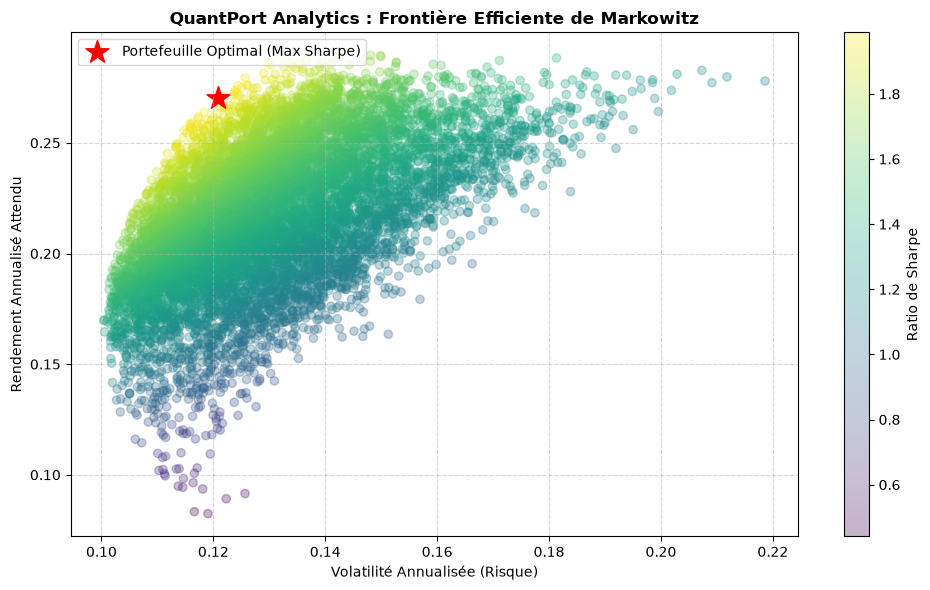

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- ÉTAPE 3 : Simulation de Monte-Carlo (10 000 Portefeuilles) ---")

num_portfolios = 10000
all_weights = np.zeros((num_portfolios, len(tickers)))
portfolio_returns = np.zeros(num_portfolios)
portfolio_volatilities = np.zeros(num_portfolios)
portfolio_sharpes = np.zeros(num_portfolios)

risk_free_rate = 0.03  # Taux sans risque hypothétique (3%)
mean_daily_returns = returns.mean()
cov_matrix = returns.cov() * 252

np.random.seed(42)
for i in range(num_portfolios):
    weights = np.random.random(len(tickers))
    weights /= np.sum(weights)  # Normalisation : la somme des poids vaut 1 (100%)
    all_weights[i, :] = weights
    
    # Calcul du rendement et de la volatilité annualisés du portefeuille
    portfolio_returns[i] = np.sum(mean_daily_returns * weights) * 252
    portfolio_volatilities[i] = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    
    # Calcul du Ratio de Sharpe
    portfolio_sharpes[i] = (portfolio_returns[i] - risk_free_rate) / portfolio_volatilities[i]

# Test de contrôle : Identification du Portefeuille Optimal (Max Sharpe)
max_sharpe_idx = np.argmax(portfolio_sharpes)
optimal_weights = all_weights[max_sharpe_idx]

print(f"• Somme des poids du portefeuille optimal : {np.sum(optimal_weights):.4f} (Doit être égal à 1.0)")
print(f"• Ratio de Sharpe Maximal : {portfolio_sharpes[max_sharpe_idx]:.4f}\n")

print("🏆 ALLOCATION DU PORTEFEUILLE OPTIMAL :")
for t, w in zip(tickers, optimal_weights):
    print(f"   • {t} : {w*100:.2f}%")

# --- VISUALISATION GRAPHIQUE : La Frontière Efficiente ---
plt.figure(figsize=(10, 6))
plt.scatter(portfolio_volatilities, portfolio_returns, c=portfolio_sharpes, cmap='viridis', marker='o', alpha=0.3)
plt.colorbar(label='Ratio de Sharpe')

# Point rouge pour le portefeuille optimal
plt.scatter(portfolio_volatilities[max_sharpe_idx], portfolio_returns[max_sharpe_idx], 
            color='red', marker='*', s=300, label='Portefeuille Optimal (Max Sharpe)')

plt.title("QuantPort Analytics : Frontière Efficiente de Markowitz", fontsize=12, fontweight='bold')
plt.xlabel("Volatilité Annualisée (Risque)")
plt.ylabel("Rendement Annualisé Attendu")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [6]:
print("--- ÉTAPE 4 : Analyse des risques extrêmes du Portefeuille Optimal ---")

# 1. Calcul de la série temporelle des rendements historiques de notre portefeuille optimal
opt_portfolio_returns = returns.dot(optimal_weights)

# 2. Le Ratio de Sortino (Ne pénalise que la volatilité baissière)
risk_free_rate = 0.03
negative_returns = opt_portfolio_returns[opt_portfolio_returns < 0]
downside_std = np.sqrt(np.mean(negative_returns**2)) * np.sqrt(252)
portfolio_ann_return = np.sum(mean_daily_returns * optimal_weights) * 252
sortino_ratio = (portfolio_ann_return - risk_free_rate) / downside_std

# 3. L'Expected Shortfall / CVaR 95% (Perte moyenne lors des pires jours)
var_95 = np.percentile(opt_portfolio_returns, 5)
cvar_95 = opt_portfolio_returns[opt_portfolio_returns <= var_95].mean()

# 4. Le Maximum Drawdown (La pire chute du sommet au creux)
cumulative = (1 + opt_portfolio_returns).cumprod()
peak = cumulative.cummax()
drawdown = (cumulative - peak) / peak
max_drawdown = drawdown.min()

# Affichage des résultats propres dans la console
print(f"• Ratio de Sortino                 : {sortino_ratio:.4f}")
print(f"• VaR Journalière (95% de conf.)   : {var_95:.2%}")
print(f"• Expected Shortfall (CVaR 95%)    : {cvar_95:.2%}")
print(f"• Maximum Drawdown (Pire chute)    : {max_drawdown:.2%}")
print("-> Crash-test de risque validé avec succès !")

--- ÉTAPE 4 : Analyse des risques extrêmes du Portefeuille Optimal ---
• Ratio de Sortino                 : 2.0347
• VaR Journalière (95% de conf.)   : -1.05%
• Expected Shortfall (CVaR 95%)    : -1.63%
• Maximum Drawdown (Pire chute)    : -8.86%
-> Crash-test de risque validé avec succès !


--- ÉTAPE 4 : Génération des graphiques de risques extrêmes ---


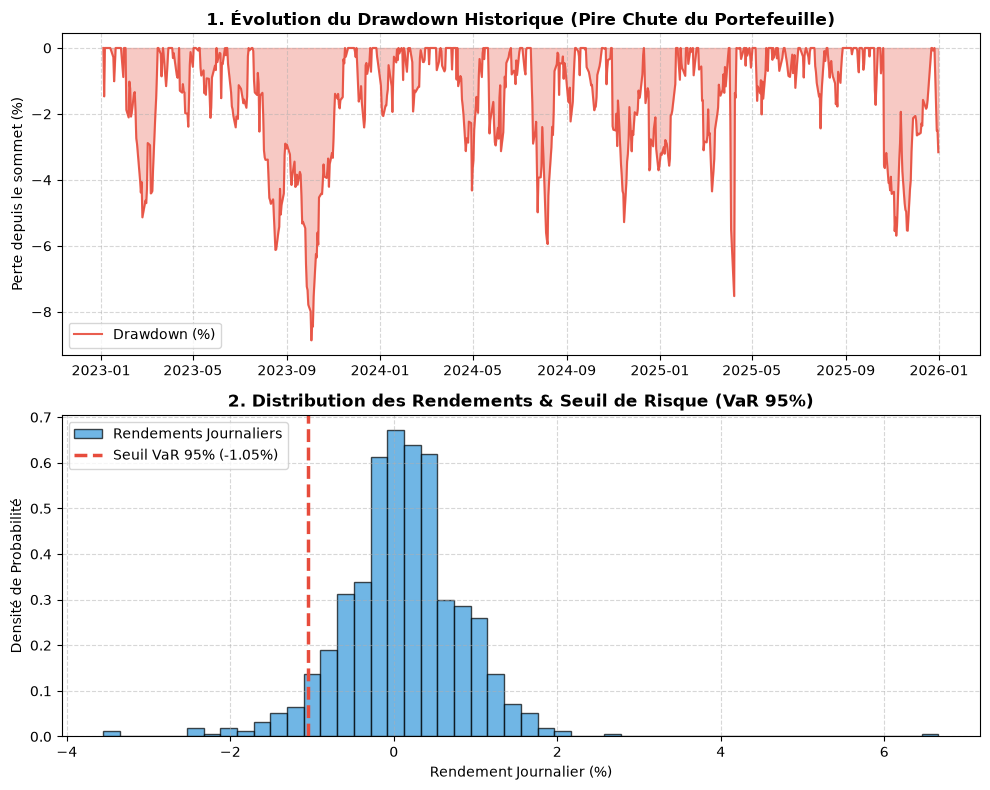

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- ÉTAPE 4 : Génération des graphiques de risques extrêmes ---")

# Calcul des rendements du portefeuille optimal
opt_portfolio_returns = returns.dot(optimal_weights)

# 1. Calcul du Drawdown
cumulative = (1 + opt_portfolio_returns).cumprod()
peak = cumulative.cummax()
drawdown = (cumulative - peak) / peak

# 2. Calcul de la VaR 95%
var_95 = np.percentile(opt_portfolio_returns, 5)

# Création de la figure avec 2 graphiques superposés
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# --- GRAPHIQUE 1 : Maximum Drawdown Historique ---
ax1.plot(drawdown.index, drawdown * 100, color='#e74c3c', alpha=0.9, label='Drawdown (%)')
ax1.fill_between(drawdown.index, drawdown * 100, 0, color='#e74c3c', alpha=0.3)
ax1.set_title("1. Évolution du Drawdown Historique (Pire Chute du Portefeuille)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Perte depuis le sommet (%)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower left")

# --- GRAPHIQUE 2 : Distribution des Rendements & Seuil de VaR ---
ax2.hist(opt_portfolio_returns * 100, bins=50, color='#3498db', edgecolor='black', alpha=0.7, density=True, label='Rendements Journaliers')
ax2.axvline(var_95 * 100, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Seuil VaR 95% ({var_95*100:.2f}%)')
ax2.set_title("2. Distribution des Rendements & Seuil de Risque (VaR 95%)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Densité de Probabilité")
ax2.set_xlabel("Rendement Journalier (%)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

--- ÉTAPE 5 : Backtest Comparatif (Portefeuille Optimal vs S&P 500) ---


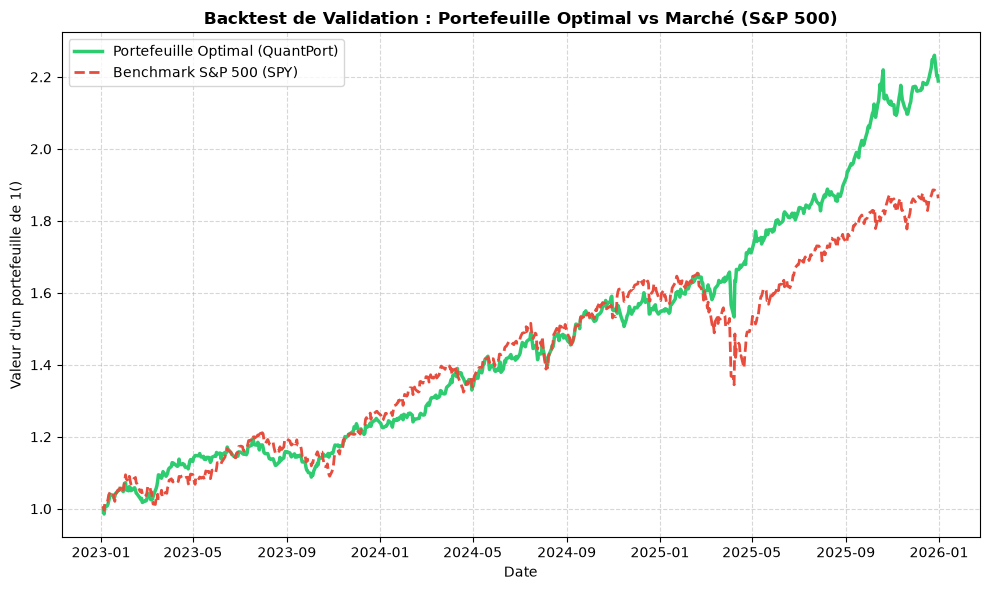

-> Backtest généré avec succès ! Regarde si ta courbe verte dépasse la courbe rouge.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- ÉTAPE 5 : Backtest Comparatif (Portefeuille Optimal vs S&P 500) ---")

# 1. Rendements du portefeuille optimal vs l'indice S&P 500 (SPY) seul
opt_portfolio_returns = returns.dot(optimal_weights)
benchmark_returns = returns['SPY']

# 2. Calcul de la croissance de 1$ investi (Performance cumulée)
portfolio_cumulative = (1 + opt_portfolio_returns).cumprod()
benchmark_cumulative = (1 + benchmark_returns).cumprod()

# 3. Génération du graphique de backtest
plt.figure(figsize=(10, 6))
plt.plot(portfolio_cumulative.index, portfolio_cumulative, color='#2ecc71', linewidth=2.5, label='Portefeuille Optimal (QuantPort)')
plt.plot(benchmark_cumulative.index, benchmark_cumulative, color='#e74c3c', linestyle='--', linewidth=2, label='Benchmark S&P 500 (SPY)')

plt.title("Backtest de Validation : Portefeuille Optimal vs Marché (S&P 500)", fontsize=12, fontweight='bold')
plt.ylabel("Valeur d'un portefeuille de 1$ ($)")
plt.xlabel("Date")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("-> Backtest généré avec succès ! Regarde si ta courbe verte dépasse la courbe rouge.")